# HW4 

Name: Krishna Karthik Kotamraju
GitHub Username: karthik05k9
USC ID: 9984105385

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Packages used: numpy, pandas, scipy (only the normal distribution), matplotlib and scikit-learn.

In [46]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import norm
from sklearn.feature_selection import RFE, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

The AReM data has one folder per activity (7 folders, 88 csv files). It is read from `Homework 4 Data/AReM` (or `data/AReM`).

In [47]:
data_dir = Path('Homework 4 Data/AReM')
if not data_dir.exists():
    data_dir = Path('data/AReM')

activities = ['bending1', 'bending2', 'cycling', 'lying',
              'sitting', 'standing', 'walking']
sensor_columns = ['avg_rss12', 'var_rss12', 'avg_rss13',
                  'var_rss13', 'avg_rss23', 'var_rss23']
print('Activity folders:', len(activities))
print('CSV files:', sum(len(list((data_dir / a).glob('dataset*.csv')))
                        for a in activities))

Activity folders: 7
CSV files: 88


### (b) Test and Train Data

Datasets 1 and 2 of `bending1`/`bending2` and datasets 1, 2, 3 of the other folders are the test set, everything else is training data.

Two files need cleaning: `bending2/dataset4.csv` is separated by spaces instead of commas (handled by the reader below), and
`sitting/dataset8.csv` has 479 rows instead of 480 (kept as it is, since `np.array_split` cuts a series of any length into pieces).

In [48]:
instances = []
for activity in activities:
    files = sorted((data_dir / activity).glob('dataset*.csv'),
                   key=lambda path: int(path.stem.replace('dataset', '')))
    for file in files:
        number = int(file.stem.replace('dataset', ''))
        test_numbers = (1, 2) if activity.startswith('bending') else (1, 2, 3)
        split = 'test' if number in test_numbers else 'train'
        separator = r'\s+' if activity == 'bending2' and number == 4 else ','
        data = pd.read_csv(file, skiprows=5, header=None, sep=separator,
                           names=['time'] + sensor_columns, usecols=range(7))
        instances.append({'activity': activity, 'file': file.name,
                          'split': split, 'data': data})

split_counts = pd.crosstab(
    pd.Series([item['activity'] for item in instances], name='Activity'),
    pd.Series([item['split'] for item in instances], name='Split'))
display(split_counts)
print('Training instances:', sum(item['split'] == 'train' for item in instances))
print('Test instances:', sum(item['split'] == 'test' for item in instances))
print('Files with fewer than 480 readings:',
      [(item['activity'], item['file'], len(item['data']))
       for item in instances if len(item['data']) != 480])

Split,test,train
Activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


Training instances: 69
Test instances: 19
Files with fewer than 480 readings: [('sitting', 'dataset8.csv', 479)]


### (c) Feature Extraction

#### i. Research

Common time-domain features for time series classification:

- location: minimum, maximum, mean, median, first and third quartile
- spread: standard deviation, variance, range, interquartile range
- shape of the distribution: skewness, kurtosis
- dependence over time: autocorrelation at some lags, cross-correlation between two series
- other: number of peaks or zero/mean crossings, total energy (sum of squares), slope of a linear trend, orders of an
  estimated ARIMA model

Only the seven features asked for in part ii are computed below.

#### ii. Extraction

In [49]:
feature_rows = []
instance_info = []
for item in instances:
    row = {}
    for number, column in enumerate(sensor_columns, start=1):
        values = item['data'][column]
        row[f'min{number}'] = values.min()
        row[f'max{number}'] = values.max()
        row[f'mean{number}'] = values.mean()
        row[f'median{number}'] = values.median()
        row[f'std{number}'] = values.std()
        row[f'q1_{number}'] = values.quantile(0.25)
        row[f'q3_{number}'] = values.quantile(0.75)
    feature_rows.append(row)
    instance_info.append((item['activity'], item['file'], item['split']))

index = pd.Index(range(1, len(feature_rows) + 1), name='Instance')
features = pd.DataFrame(feature_rows, index=index)
instance_info = pd.DataFrame(instance_info, index=index,
                             columns=['Activity', 'File', 'Split'])
print('Feature table shape:', features.shape)
features.round(3).head(8)

Feature table shape: (88, 42)


,min1,max1,mean1,median1,std1,q1_1,q3_1,min2,max2,mean2,...,std5,q1_5,q3_5,min6,max6,mean6,median6,std6,q1_6,q3_6
Instance,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.625,40.50,1.477,39.250,42.00,0.0,1.30,0.359,...,2.188,33.000,36.00,0.0,1.92,0.571,0.43,0.583,0.00,1.30
2,38.00,45.67,42.813,42.50,1.436,42.000,43.67,0.0,1.22,0.372,...,1.995,32.000,34.50,0.0,3.11,0.571,0.43,0.601,0.00,1.30
3,35.00,47.40,43.954,44.33,1.559,43.000,45.00,0.0,1.70,0.426,...,2.000,35.362,36.50,0.0,1.79,0.493,0.43,0.514,0.00,0.94
4,33.00,47.75,42.180,43.50,3.671,39.150,45.00,0.0,3.00,0.696,...,3.849,30.458,36.33,0.0,2.18,0.614,0.50,0.524,0.00,1.00
5,33.00,45.75,41.678,41.75,2.243,41.330,42.75,0.0,2.83,0.536,...,2.411,28.458,31.25,0.0,1.79,0.383,0.43,0.389,0.00,0.50
6,37.00,48.00,43.455,43.25,1.386,42.500,45.00,0.0,1.58,0.378,...,2.489,22.250,24.00,0.0,5.26,0.680,0.50,0.623,0.43,0.87
7,36.25,48.00,43.969,44.50,1.618,43.310,44.67,0.0,1.50,0.413,...,3.318,20.500,23.75,0.0,2.96,0.555,0.49,0.488,0.00,0.83
8,12.75,51.00,24.563,24.25,3.738,23.188,26.50,0.0,6.87,0.591,...,3.694,20.500,27.00,0.0,4.97,0.700,0.50,0.694,0.43,0.87


#### iii. Standard Deviation and 90% Bootstrap Confidence Intervals

For each of the 42 columns the standard deviation is computed over the 88 instances. A bootstrap sample draws 88 instances with
replacement; the 5th and 95th percentiles of 1,000 bootstrap estimates give a 90% percentile interval. The sample standard
deviation (`ddof=1`) is used for the estimate and inside the bootstrap.

In [50]:
rng = np.random.default_rng(552)
results = []
for feature in features.columns:
    values = features[feature].to_numpy()
    bootstrap_stds = []
    for _ in range(1000):
        sample = rng.choice(values, size=len(values), replace=True)
        bootstrap_stds.append(np.std(sample, ddof=1))
    lower, upper = np.percentile(bootstrap_stds, [5, 95])
    results.append((feature, features[feature].std(), lower, upper))

std_intervals = pd.DataFrame(
    results, columns=['Feature', 'Std. Dev.', '90% Lower', '90% Upper']
).set_index('Feature')
with pd.option_context('display.max_rows', None):
    display(std_intervals.round(3))

,Std. Dev.,90% Lower,90% Upper
Feature,,,
min1,9.570,8.235,10.689
max1,4.394,3.390,5.220
mean1,5.336,4.700,5.874
median1,5.440,4.817,6.005
std1,1.772,1.582,1.945
q1_1,6.154,5.594,6.658
q3_1,5.139,4.299,5.814
min2,0.000,0.000,0.000
max2,5.063,4.629,5.398


#### iv. Select Features

Two criteria are used to choose the three features: whether a feature varies across the instances, and how much it repeats the information already in the mean.

In [51]:
print('Features with zero spread across the 88 instances:',
      std_intervals.index[std_intervals['Std. Dev.'] == 0].tolist())

# average (over the 6 series) correlation of each statistic with the mean of the same series
pairs = [('minimum', 'min'), ('maximum', 'max'), ('median', 'median'),
         ('standard deviation', 'std'), ('1st quartile', 'q1_'), ('3rd quartile', 'q3_')]
with warnings.catch_warnings():
    warnings.simplefilter('ignore')   # min2 and min4 are constant, their correlation is undefined
    corr_with_mean = {name: np.nanmean([features[f'mean{k}'].corr(features[f'{prefix}{k}'])
                                        for k in range(1, 7)])
                      for name, prefix in pairs}
print()
print(pd.Series(corr_with_mean, name='mean correlation with the mean').round(3))

Features with zero spread across the 88 instances: ['min2', 'min4']

minimum               0.598
maximum               0.791
median                0.992
standard deviation    0.392
1st quartile          0.981
3rd quartile          0.985
Name: mean correlation with the mean, dtype: float64


- `min2` and `min4` are 0 in every instance (standard deviation 0), so they carry no information.
- The median and the two quartiles follow the mean closely (average correlation 0.98 to 0.99), so they repeat what the mean already gives.
- The minimum (0.60), the maximum (0.79) and the standard deviation (0.39) have lower correlation with the mean. The standard deviation is the least explained by the mean, and the maximum adds information about the highest readings.

Selected features: **mean, standard deviation and maximum** of each series.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

Set-up used in the whole of part 2: the three chosen features (mean, standard deviation, maximum) of each of the 6 series are computed on
each of the `l` pieces a series is cut into, so an instance has `18*l` features. The features for every `l` from 1 to 20 are computed
once here, for both the training and the test set. The pieces are cut with `np.array_split`, so they are of equal length up to one reading.

The three statistics are carried over from HW3. The correlation table above summarizes those choices across all 88 instances; it is not used to tune the classifiers. The values of `l`, `p`, and `C` are selected using cross-validation on the training set. CV splits, random sampling and stochastic solvers use seed 552 to improve reproducibility.

In [52]:
SEED = 552
STATS = ['mean', 'std', 'max']

train_items = [it for it in instances if it['split'] == 'train']
test_items = [it for it in instances if it['split'] == 'test']
train_arrays = [it['data'][sensor_columns].to_numpy() for it in train_items]
test_arrays = [it['data'][sensor_columns].to_numpy() for it in test_items]

# labels: bending (bending1 + bending2) vs the rest, and the 7 activities
y_train = np.array([int(it['activity'].startswith('bending')) for it in train_items])
y_test = np.array([int(it['activity'].startswith('bending')) for it in test_items])
y_train_multi = np.array([it['activity'] for it in train_items])
y_test_multi = np.array([it['activity'] for it in test_items])


def segment_features(arrays, l):
    # cut every series into l pieces, then take mean, std and max of each series in each piece
    rows = []
    for arr in arrays:
        row = []
        for piece in np.array_split(arr, l, axis=0):
            row += list(piece.mean(axis=0))
            row += list(piece.std(axis=0, ddof=1))
            row += list(piece.max(axis=0))
        rows.append(row)
    names = [f'seg{p}_{s}{k}' for p in range(1, l + 1) for s in STATS for k in range(1, 7)]
    return pd.DataFrame(rows, columns=names)


Xtr = {l: segment_features(train_arrays, l) for l in range(1, 21)}
Xte = {l: segment_features(test_arrays, l) for l in range(1, 21)}

print('Class counts in the training set (other, bending):', np.bincount(y_train))
print('Class counts in the test set     (other, bending):', np.bincount(y_test))
print('Shape of the l = 1 and l = 3 training features:', Xtr[1].shape, Xtr[3].shape)
Xtr[1].head(3).round(3)

Class counts in the training set (other, bending): [60  9]
Class counts in the test set     (other, bending): [15  4]
Shape of the l = 1 and l = 3 training features: (69, 18) (69, 54)


,seg1_mean1,seg1_mean2,seg1_mean3,seg1_mean4,seg1_mean5,seg1_mean6,seg1_std1,seg1_std2,seg1_std3,seg1_std4,seg1_std5,seg1_std6,seg1_max1,seg1_max2,seg1_max3,seg1_max4,seg1_max5,seg1_max6
0,43.954,0.426,22.122,0.497,35.588,0.493,1.559,0.339,3.031,0.551,2.000,0.514,47.40,1.70,29.75,4.44,38.50,1.79
1,42.180,0.696,22.184,0.990,33.494,0.614,3.671,0.631,3.810,0.954,3.849,0.524,47.75,3.00,30.00,5.15,38.67,2.18
2,41.678,0.536,19.007,0.842,29.857,0.383,2.243,0.405,4.087,0.929,2.411,0.389,45.75,2.83,28.25,6.42,37.50,1.79


### (a) Binary Classification Using Logistic Regression

#### i. Plots

Scatter plots of the mean, standard deviation and maximum of series 1, 2 and 6, two features at a time. Orange is bending, blue is everything else.

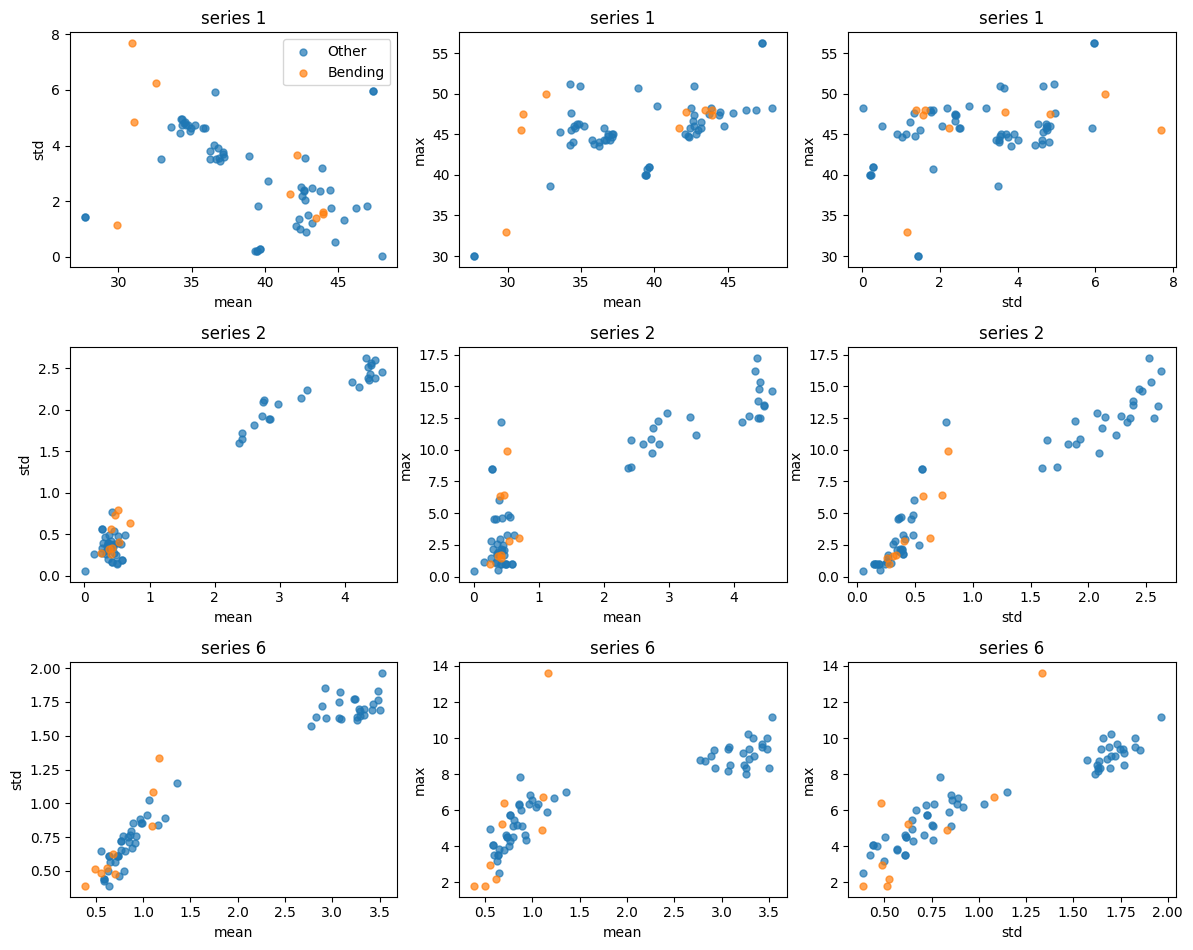

In [53]:
def scatter_plots(l, series=(1, 2, 6)):
    X = Xtr[l]
    pairs = [('mean', 'std'), ('mean', 'max'), ('std', 'max')]
    fig, axes = plt.subplots(l * len(series), 3, figsize=(12, 3.2 * l * len(series)), squeeze=False)
    for p in range(1, l + 1):
        for r, k in enumerate(series):
            for c, (a, b) in enumerate(pairs):
                ax = axes[(p - 1) * len(series) + r, c]
                for label, color, name in [(0, 'tab:blue', 'Other'), (1, 'tab:orange', 'Bending')]:
                    m = y_train == label
                    ax.scatter(X.loc[m, f'seg{p}_{a}{k}'], X.loc[m, f'seg{p}_{b}{k}'],
                               s=25, alpha=0.7, color=color, label=name)
                ax.set_xlabel(a)
                ax.set_ylabel(b)
                ax.set_title(f'series {k}' if l == 1 else f'piece {p} of {l}, series {k}')
    axes[0, 0].legend()
    fig.tight_layout()
    plt.show()


scatter_plots(1)

In series 1, the two classes overlap, although some bending points have unusually large standard deviations. In series 2 and 6, bending points mostly have low means, but other activities also occur in the same region. None of the displayed feature pairs clearly separates bending from the other activities.

#### ii. Split Plots

The same plots when every series is cut into two halves (rows are piece 1 and piece 2 of series 1, 2 and 6).

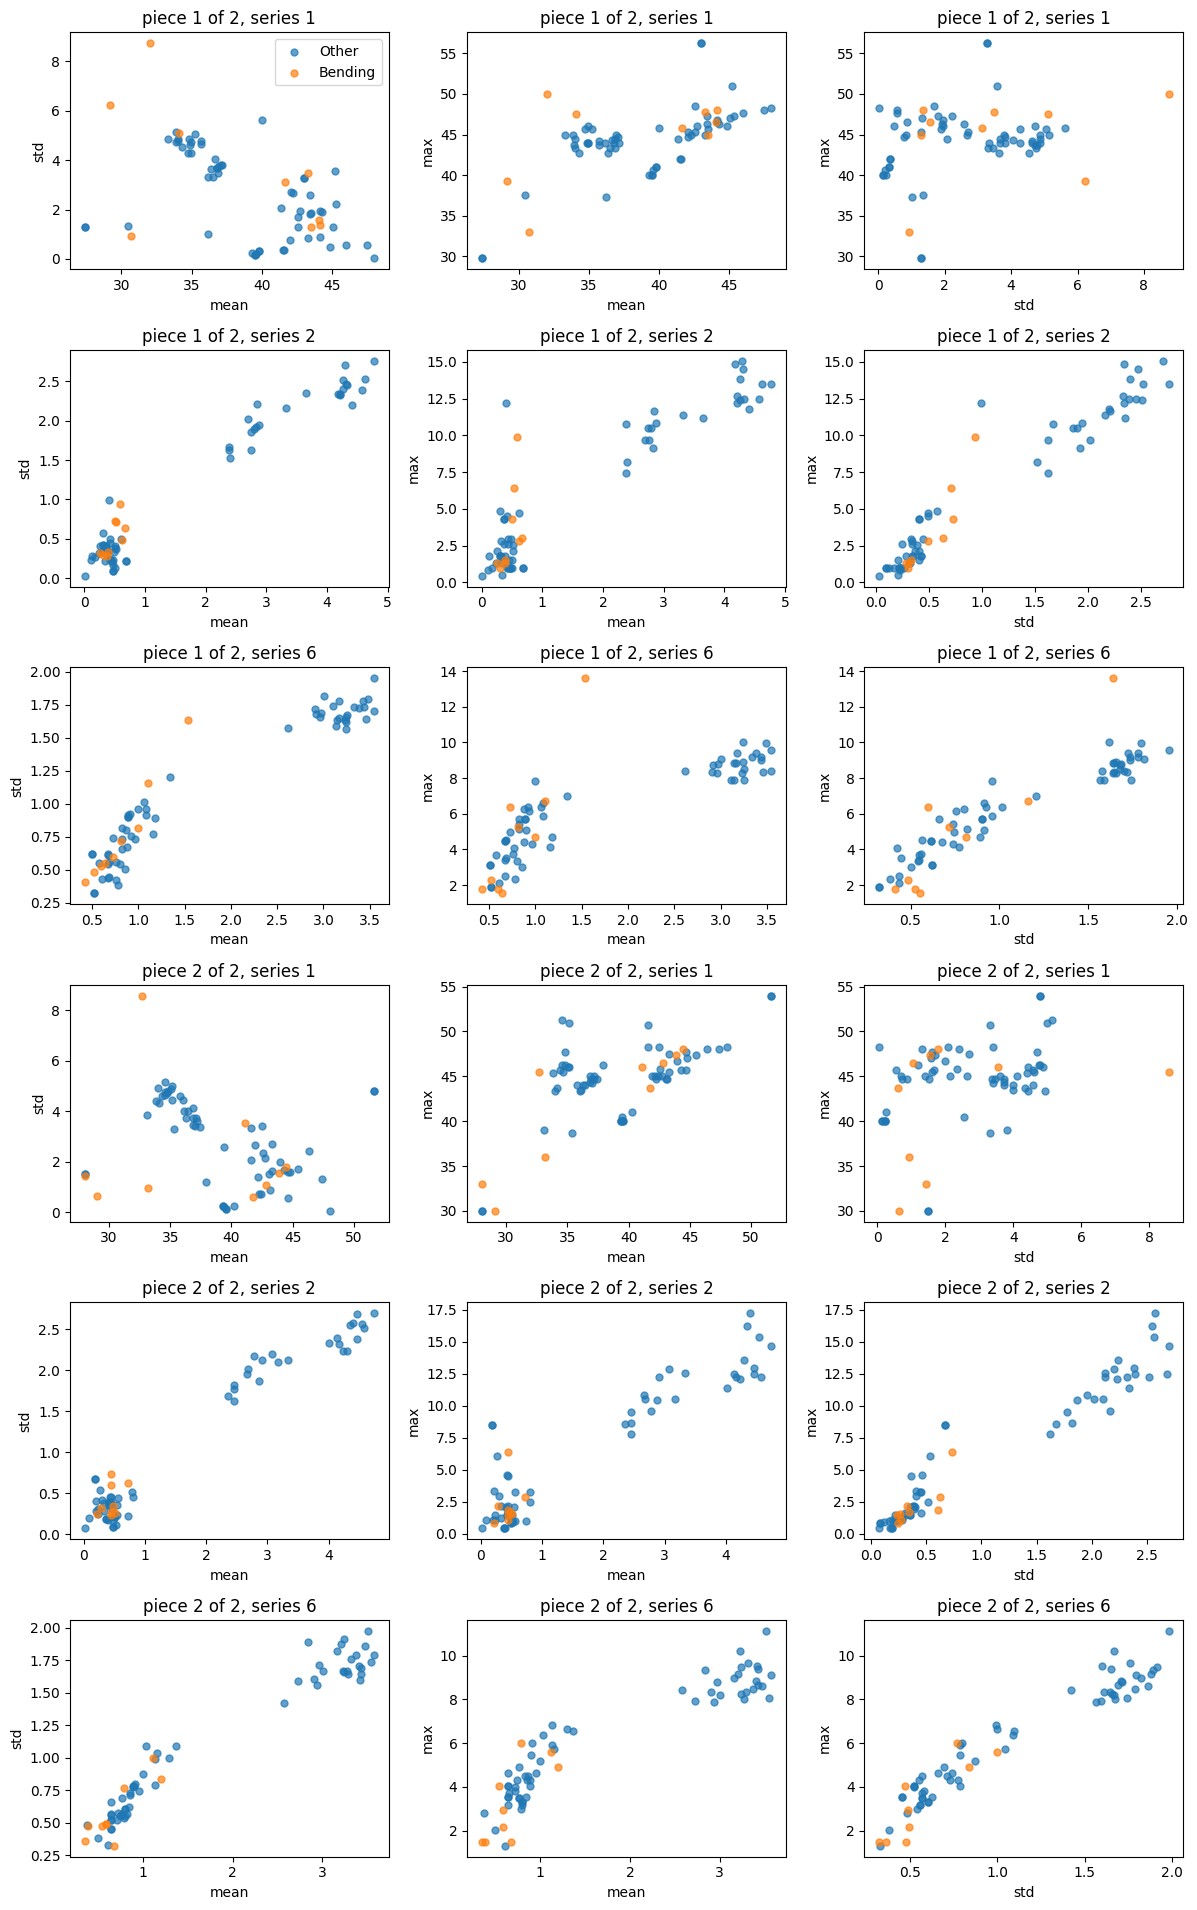

In [54]:
scatter_plots(2)

In [55]:
# group means of the features, whole series (l = 1) and each half (l = 2)
cols = [f'{s}{k}' for k in (1, 2, 6) for s in ('mean', 'std', 'max')]
whole = Xtr[1].rename(columns=lambda c: c.replace('seg1_', ''))[cols]
halves = Xtr[2]
summary = pd.concat({
    'whole': whole.groupby(y_train).mean(),
    'half 1': halves[[f'seg1_{c}' for c in cols]].rename(columns=lambda c: c.replace('seg1_', '')).groupby(y_train).mean(),
    'half 2': halves[[f'seg2_{c}' for c in cols]].rename(columns=lambda c: c.replace('seg2_', '')).groupby(y_train).mean(),
}, axis=0)
summary.index.names = ['piece', 'bending']
summary.round(2)

mean1  std1   max1  mean2  std2  max2  mean6  std6  max6
piece  bending                                                          
whole  0        39.19  2.94  45.36   1.67  1.08  6.72   1.78  1.10  6.70
       1        37.74  3.38  45.88   0.45  0.48  3.81   0.75  0.70  5.07
half 1 0        39.06  2.59  44.32   1.67  1.06  6.03   1.77  1.09  6.24
       1        38.07  3.53  44.75   0.47  0.53  3.50   0.82  0.77  4.90
half 2 0        39.33  2.76  44.79   1.67  1.08  6.13   1.78  1.09  6.12
       1        37.42  2.23  41.79   0.44  0.41  2.23   0.69  0.58  3.36

The plots of the two halves look like the plot of the whole series: the same two groups of points appear in series 2 and 6, and the bending points stay in the low-value region mixed with the other class. The table of group means agrees: the mean of series 2 is 0.45 for bending and 1.67 for the rest on the whole series, and 0.47 / 1.67 and 0.44 / 1.67 on the first and second half. The second half of the bending series has a smaller standard deviation and maximum than the first half (max of series 2: 3.50 in the first half, 2.23 in the second). There is no considerable difference from 2(a)i: splitting the series does not separate the classes better.

#### iii. Time Series Segments

For each `l` from 1 to 20 every series is cut into `l` pieces, which gives `18*l` features, and a logistic regression with practically no penalty (`C = 10^4`) is fitted. Variables are removed by recursive feature elimination (backward selection, one variable at a time), and `RFECV` chooses the number of features `p` with 5-fold cross-validation. The best pair `(l, p)` has the highest CV accuracy; ties go to the smaller `p` and then to the smaller `l`.

**Backward selection (RFE)** is used instead of pruning by p-values, which the assignment allows. For l ≥ 4 there are more features than the 69 training instances, so the information matrix is singular, and with nearly separated classes Wald p-values are unreliable. P-values are therefore reported only for the final selected model (part iv)

**Stratified CV.** Only 9 of the 69 training instances are bending. In stratified cross-validation every fold keeps approximately the same share of each class as the training set, so no fold is left without a bending instance. The folds are shuffled with a fixed seed.

**The right way and the wrong way.**  Scaling and feature elimination must be fitted separately within each training fold, then evaluated on the held-out fold. The RFECV estimator uses a pipeline to do this. Selecting features on the entire training set before cross-validation is the wrong approach because the validation labels influence feature selection. This can give an overly optimistic CV score, although the wrong-way score is not necessarily higher in every run. In the table below, it is equal to or higher than the correct score for 16 of the 20 values of l.

In [56]:
# Nested CV at the chosen l: RFECV picks p using only each outer training fold,
# and the outer held-out fold scores it. cv5 chooses p, so the outer splits use a different seed.
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
inner = RFECV(logreg_nopenalty(), step=1, cv=cv5, scoring='accuracy',
              importance_getter=GETTER)
nested = cross_val_score(inner, Xtr[best_l], y_train, cv=outer_cv, scoring='accuracy')
print(f'Non-nested CV accuracy at l={best_l}: {best_cv:.3f}')
print(f'Nested CV accuracy at l={best_l}:     {nested.mean():.3f}')

Non-nested CV accuracy at l=3: 0.986
Nested CV accuracy at l=3:     0.914


0.986 is not a nested estimate: the same 5-fold splits choose p and report the score, so it is slightly optimistic. A nested check at l = 3 gives 0.914

In [57]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
GETTER = 'named_steps.logisticregression.coef_'


def logreg_nopenalty():
    # C is huge, so the L2 penalty of sklearn has practically no effect; the scaler is part of
    # the pipeline, so it is refitted inside every training fold
    return make_pipeline(StandardScaler(),
                         LogisticRegression(C=1e4, solver='liblinear', max_iter=300, random_state=SEED))


rows, selectors = [], {}
for l in range(1, 21):
    rfecv = RFECV(logreg_nopenalty(), step=1, cv=cv5, scoring='accuracy',
                  importance_getter=GETTER)
    rfecv.fit(Xtr[l], y_train)
    selectors[l] = rfecv
    rows.append((l, rfecv.n_features_, rfecv.cv_results_['mean_test_score'].max()))

rfe_scores = pd.DataFrame(rows, columns=['l', 'p', 'CV accuracy (right way)'])

# wrong way: select p features on ALL the training data first, then cross-validate on the selected columns
wrong = []
for l, p in zip(rfe_scores['l'], rfe_scores['p']):
    rfe_all = RFE(logreg_nopenalty(), n_features_to_select=int(p), step=1,
                  importance_getter=GETTER).fit(Xtr[l], y_train)
    wrong.append(cross_val_score(logreg_nopenalty(), Xtr[l].loc[:, rfe_all.support_],
                                 y_train, cv=cv5, scoring='accuracy').mean())
rfe_scores['CV accuracy (wrong way)'] = wrong
print(rfe_scores.round(3).to_string(index=False))

# best pair: highest CV accuracy, ties go to fewer features and then to smaller l
best = rfe_scores.sort_values(['CV accuracy (right way)', 'p', 'l'],
                              ascending=[False, True, True]).iloc[0]
best_l, best_p = int(best['l']), int(best['p'])
best_cv = best['CV accuracy (right way)']
selected = Xtr[best_l].columns[selectors[best_l].support_].tolist()
print()
print('Best (l, p):', (best_l, best_p), ' CV accuracy:', round(best_cv, 3))
print('Selected features:', selected)

 l   p  CV accuracy (right way)  CV accuracy (wrong way)
 1   1                    0.943                    0.943
 2   1                    0.914                    0.943
 3   1                    0.986                    0.971
 4   1                    0.943                    0.943
 5   1                    0.957                    0.870
 6   2                    0.957                    0.943
 7   5                    0.957                    0.986
 8   1                    0.957                    0.943
 9   5                    0.943                    1.000
10  11                    0.957                    1.000
11   8                    0.986                    1.000
12   2                    0.971                    0.971
13   1                    0.957                    0.957
14   6                    0.986                    0.986
15 173                    0.957                    0.957
16   7                    0.971                    1.000
17  13                    0.971

The right-way CV accuracies are between 0.914 and 0.986. One instance corresponds to 1/69 = 0.0145, so many values of `l` have similar CV accuracies. Four values (`l` = 3, 11, 14, 20) reach the maximum 0.986. The tie-break gives **(l, p) = (3, 1)**: one feature, `seg1_mean5`, which is the mean of series 5 (`avg_rss23`) in the first of the 3 pieces.

The wrong-way column is equal to or higher than the right-way column for 16 of the 20 values of `l`, and it is 1.000 for 7 values (`l` = 9, 10, 11, 16, 17, 19, 20), which the right way never reaches.

#### iv. Confusion Matrix, ROC and Coefficients on the Training Set

The final model is refitted using the selected feature. Since the feature is standardized, its coefficient describes the change in the log-odds of bending for a one-standard-deviation increase. Standard errors are calculated from the information matrix X'WX, where W contains p(1 − p). Dividing each coefficient by its standard error gives a Wald z-statistic; the two-sided p-value is calculated as 2Φ(−|z|). These are approximate p-values from the final fitted model. They do not account for the earlier feature selection, and near separation makes their interpretation less reliable.

Training set: accuracy = 0.971, AUC = 0.993
                predicted other  predicted bending
actual other                 59                  1
actual bending                1                  8



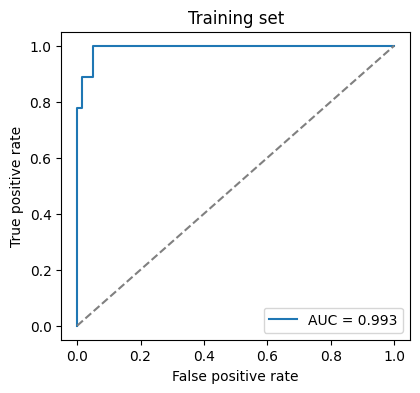

,coefficient,std. error,p-value
intercept,-9.9720,6.9832,0.1533
seg1_mean5,16.5663,12.5775,0.1878


In [58]:
def binary_report(y, prob, name, ax=None):
    pred = (prob >= 0.5).astype(int)
    auc = roc_auc_score(y, prob)
    print(f'{name}: accuracy = {accuracy_score(y, pred):.3f}, AUC = {auc:.3f}')
    print(pd.DataFrame(confusion_matrix(y, pred, labels=[0, 1]),
                       index=['actual other', 'actual bending'],
                       columns=['predicted other', 'predicted bending']))
    print()
    if ax is not None:
        fpr, tpr, _ = roc_curve(y, prob)
        ax.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
        ax.plot([0, 1], [0, 1], '--', color='gray')
        ax.set_xlabel('False positive rate')
        ax.set_ylabel('True positive rate')
        ax.set_title(name)
        ax.legend(loc='lower right')
    return auc


def wald_table(pipe, X, names):
    # coefficients (per standard deviation of each feature) and Wald p-values from the information matrix
    Z = np.column_stack([np.ones(len(X)), pipe[0].transform(X)])
    beta = np.r_[pipe[-1].intercept_, pipe[-1].coef_.ravel()]
    p_hat = 1 / (1 + np.exp(-Z @ beta))
    info = (Z * (p_hat * (1 - p_hat))[:, None]).T @ Z
    se = np.sqrt(np.diag(np.linalg.pinv(info)))
    return pd.DataFrame({'coefficient': beta, 'std. error': se,
                         'p-value': 2 * norm.sf(np.abs(beta / se))},
                        index=['intercept'] + list(names))


Xtr_best, Xte_best = Xtr[best_l][selected], Xte[best_l][selected]
final_model = logreg_nopenalty().fit(Xtr_best, y_train)

fig, ax = plt.subplots(figsize=(4.5, 4))
binary_report(y_train, final_model.predict_proba(Xtr_best)[:, 1], 'Training set', ax)
plt.show()
wald_table(final_model, Xtr_best, selected).round(4)

On the training set 59 of 60 other instances and 8 of 9 bending instances are classified correctly: accuracy 0.971, AUC 0.993.

The fitted model is `logit(P(bending)) = -9.97 + 16.57 * z`, with `z` the standardized `seg1_mean5`. The p-values are 0.153 for the intercept and 0.188 for the coefficient. The standard errors (6.98 and 12.58) are large compared with the coefficients, which happens when the classes are almost perfectly separated (see vi).

#### v. Test the Classifier

Test set: accuracy = 0.842, AUC = 0.900
                predicted other  predicted bending
actual other                 13                  2
actual bending                1                  3



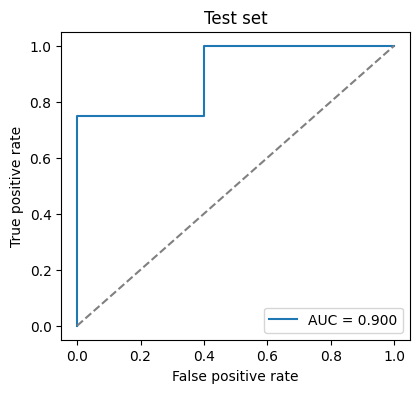

Cross-validation accuracy of the chosen (l, p): 0.986


In [59]:
fig, ax = plt.subplots(figsize=(4.5, 4))
test_prob = final_model.predict_proba(Xte_best)[:, 1]
binary_report(y_test, test_prob, 'Test set', ax)
plt.show()
print('Cross-validation accuracy of the chosen (l, p):', round(best_cv, 3))

On the test set the accuracy is **0.842** (16 of 19) and the AUC is 0.900 (2 false alarms, 1 missed bending instance). The cross-validation accuracy was 0.986, so the test accuracy is lower. 

Possible reasons visible in the results: the CV accuracy of 0.986 is not nested, since the same folds choose p and report the score (the nested estimate is 0.914); l and p were chosen as the best CV score among 20 values of l; the model uses a single feature selected from 54 candidates at l = 3; and the test set has only 19 instances (4 bending), where one instance is 1/19 = 0.053 of the accuracy.

#### vi. Separation

In [60]:
# l = 1 (all 18 features): training accuracy and largest coefficient as C grows
rows = []
for C in [1, 10, 100, 1e3, 1e4, 1e5, 1e6]:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')   # liblinear complains that it stopped at max_iter
        m = make_pipeline(StandardScaler(),
                          LogisticRegression(C=C, solver='liblinear', max_iter=1000, random_state=SEED)).fit(Xtr[1], y_train)
    rows.append((C, m.score(Xtr[1], y_train), np.abs(m[-1].coef_).max()))
print(pd.DataFrame(rows, columns=['C', 'training accuracy', 'largest |coefficient|']).to_string(index=False))

        C  training accuracy  largest |coefficient|
      1.0                1.0               1.341458
     10.0                1.0               2.562102
    100.0                1.0               4.034146
   1000.0                1.0               5.687950
  10000.0                1.0               7.420754
 100000.0                1.0               9.069016
1000000.0                1.0               9.569341


**In the training data the classes are well separated.** With all 18 features (`l = 1`) every training instance is classified correctly for every value of `C` in the table, so a hyperplane that separates the classes exists. For separable classes the likelihood keeps increasing when the coefficients grow and the maximum likelihood estimate does not exist; the table shows this: the largest coefficient grows from 1.34 at `C = 1` to 9.57 at `C = 10^6`. This is the instability mentioned in the assignment, and the reason for limiting `max_iter`.

The final one-feature model has 2 training mistakes, but it is close to separating (AUC 0.993), which agrees with its large coefficient (16.57) and large standard errors. On the test set the accuracy is 0.842, so the separation in the training data does not carry over fully to new instances.

#### vii. Imbalance and Case-Control Sampling

**The classes are imbalanced**: 9 of 69 training instances (13%) and 4 of 19 test instances are bending. In the confusion matrices the bending class is the one that is missed (1 of 4 bending instances on the test set).

**Case-control sampling.** All 9 bending instances (cases) are kept, and 9 of the 60 other instances (controls) are drawn at random, so the sample is 50/50. The logistic regression is fitted on these 18 instances. In a case-control sample the slope coefficients estimate the same quantities as in the full data, and only the intercept changes, because the sampling changed the share of bending. The log-odds of bending is 0 in the sample and `log(9/60) = -1.897` in the training data, so the intercept is corrected by adding `log(pi / (1 - pi)) = -1.897`. The same selected feature as above is used.

bending share in training data: 0.130, intercept shift: -1.897
intercept before / after the shift: 11.46 / 9.563

Case-control, training set: accuracy = 0.942, AUC = 0.993
                predicted other  predicted bending
actual other                 56                  4
actual bending                0                  9

Case-control, test set: accuracy = 0.737, AUC = 0.900
                predicted other  predicted bending
actual other                 11                  4
actual bending                1                  3



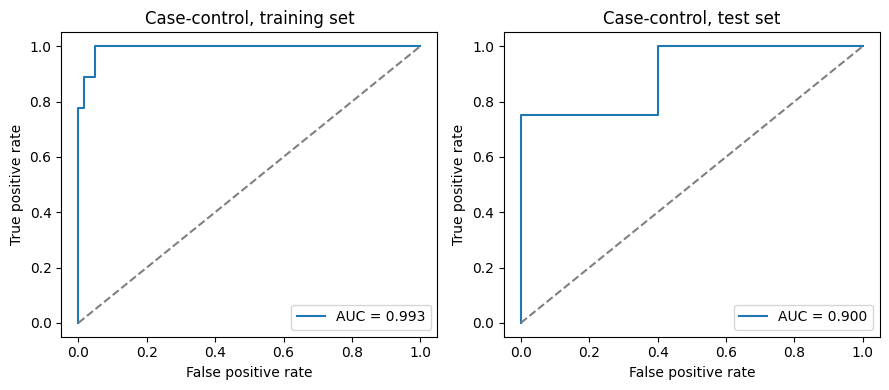

200 different draws of controls, test accuracy: 0.783 +/- 0.080, test AUC: 0.900 +/- 0.000


In [61]:
pi = y_train.mean()                          # share of bending in the population (training data)
cases = np.flatnonzero(y_train == 1)
controls = np.flatnonzero(y_train == 0)


def case_control_model(rng):
    # keep every bending instance and an equal number of randomly chosen other instances
    pick = np.r_[cases, rng.choice(controls, size=len(cases), replace=False)]
    return logreg_nopenalty().fit(Xtr_best.iloc[pick], y_train[pick])


def adjusted_prob(model, X):
    # the sample is 50/50, so the intercept is shifted by log(pi / (1 - pi)) to put the true prevalence back
    z = model.decision_function(X) + np.log(pi / (1 - pi))
    return 1 / (1 + np.exp(-z))


cc_model = case_control_model(np.random.default_rng(SEED))
print(f'bending share in training data: {pi:.3f}, intercept shift: {np.log(pi / (1 - pi)):.3f}')
print('intercept before / after the shift:',
      np.round(cc_model[-1].intercept_[0], 3), '/', np.round(cc_model[-1].intercept_[0] + np.log(pi / (1 - pi)), 3))
print()
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
binary_report(y_train, adjusted_prob(cc_model, Xtr_best), 'Case-control, training set', axes[0])
binary_report(y_test, adjusted_prob(cc_model, Xte_best), 'Case-control, test set', axes[1])
plt.tight_layout()
plt.show()

# repeat the draw of the controls 200 times
accs, aucs = [], []
rng = np.random.default_rng(SEED)
for _ in range(200):
    m = case_control_model(rng)
    pr = adjusted_prob(m, Xte_best)
    accs.append(accuracy_score(y_test, pr >= 0.5))
    aucs.append(roc_auc_score(y_test, pr))
print(f'200 different draws of controls, test accuracy: {np.mean(accs):.3f} +/- {np.std(accs):.3f}, '
      f'test AUC: {np.mean(aucs):.3f} +/- {np.std(aucs):.3f}')

With the intercept correction all 9 bending training instances are found and there are 4 false alarms (accuracy 0.942, AUC 0.993). On the test set the accuracy is 0.737 and the AUC 0.900 (3 of 4 bending found, 4 false alarms). Over 200 different draws of the controls the test accuracy is 0.783 with a standard deviation of 0.080, so the result depends on which controls are drawn.

The test AUC is 0.900 in every draw, the same as the AUC of the ordinary model. With one feature the ranking of the instances is the ranking of that feature, and the intercept shift only moves the cutoff. The test accuracy is 0.842 for the ordinary fit and 0.737 for the single draw above (0.783 on average over the draws), so case-control sampling does not improve the test accuracy; it changes the balance between missed bending instances and false alarms.

### (b) Binary Classification Using L1-penalized Logistic Regression

#### i. Time Series Segments

`l` and the L1 weight are cross-validated together. For every `l` from 1 to 20, `GridSearchCV` tries 9 values of `C` (0.01 to 100 on a log scale, `C = 1 / lambda`) with stratified 5-fold CV and keeps the best one; then the `l` with the best CV accuracy is chosen (ties go to the smaller `l`). The features are standardized inside the pipeline, since the L1 penalty depends on the scale of the features. The solver is `liblinear`.

 l       C  CV accuracy
 1   0.316        0.971
 2   0.316        0.943
 3   0.316        0.971
 4   1.000        0.957
 5   0.316        0.929
 6   0.316        0.942
 7   3.162        0.943
 8   1.000        0.942
 9 100.000        0.927
10  31.623        0.943
11   1.000        0.971
12   1.000        0.986
13   1.000        0.956
14   1.000        0.957
15   0.316        0.943
16   1.000        0.957
17   1.000        0.943
18   1.000        0.971
19   3.162        0.986
20   1.000        0.971

Best (l, C): (12, 1.0)  CV accuracy: 0.986
Nonzero coefficients: 5 out of 216
Features kept: ['seg2_mean5', 'seg3_std3', 'seg7_max1', 'seg11_mean5', 'seg11_max6']

L1, training set: accuracy = 1.000, AUC = 1.000
                predicted other  predicted bending
actual other                 60                  0
actual bending                0                  9

L1, test set: accuracy = 0.947, AUC = 0.983
                predicted other  predicted bending
actual other                 15   

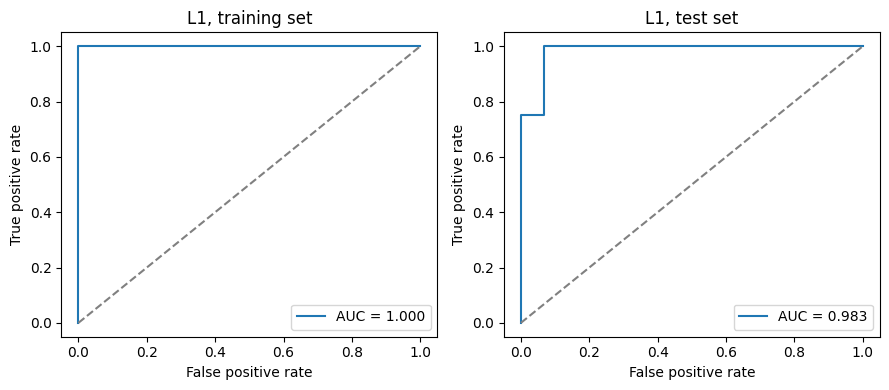

In [62]:
Cs = np.logspace(-2, 2, 9)          # C = 1 / lambda


def l1_logreg(C=1.0):
    # l1_ratio=1 is a pure L1 penalty in sklearn >= 1.8 (older versions use penalty='l1')
    major_minor = tuple(int(v) for v in sklearn.__version__.split('.')[:2])
    kw = {'l1_ratio': 1} if major_minor >= (1, 8) else {'penalty': 'l1'}
    return make_pipeline(StandardScaler(),
                         LogisticRegression(solver='liblinear', C=C, max_iter=500,random_state=SEED, **kw))


rows = []
for l in range(1, 21):
    search = GridSearchCV(l1_logreg(), {'logisticregression__C': Cs},
                          cv=cv5, scoring='accuracy').fit(Xtr[l], y_train)
    rows.append((l, search.best_params_['logisticregression__C'], search.best_score_))

l1_scores = pd.DataFrame(rows, columns=['l', 'C', 'CV accuracy'])
print(l1_scores.round(3).to_string(index=False))

best_l1 = l1_scores.sort_values(['CV accuracy', 'l'], ascending=[False, True]).iloc[0]
l1_l, l1_C = int(best_l1['l']), float(best_l1['C'])
l1_model = l1_logreg(l1_C).fit(Xtr[l1_l], y_train)
nonzero = np.flatnonzero(l1_model[-1].coef_.ravel())
print()
print('Best (l, C):', (l1_l, round(l1_C, 3)), ' CV accuracy:', round(best_l1['CV accuracy'], 3))
print(f'Nonzero coefficients: {len(nonzero)} out of {Xtr[l1_l].shape[1]}')
print('Features kept:', Xtr[l1_l].columns[nonzero].tolist())
print()
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
binary_report(y_train, l1_model.predict_proba(Xtr[l1_l])[:, 1], 'L1, training set', axes[0])
binary_report(y_test, l1_model.predict_proba(Xte[l1_l])[:, 1], 'L1, test set', axes[1])
plt.tight_layout()
plt.show()

`l` = 12 and `l` = 19 both reach a CV accuracy of 0.986; the smaller one is used, **(l, C) = (12, 1)**. The model keeps 5 of the 216 features. The training accuracy is 1.0 and the **test accuracy is 0.947 (18 of 19)** with AUC 0.983; the only mistake is one missed bending instance.

Two of the five kept features are the mean of series 5 in different pieces (`seg2_mean5`, `seg11_mean5`), the same quantity that was kept by the backward selection in part iii.

#### ii. Comparison

In [63]:
def test_acc(prob):
    return accuracy_score(y_test, prob >= 0.5)


comparison = pd.DataFrame({
    'l': [best_l, l1_l],
    'features used': [best_p, len(nonzero)],
    'CV accuracy': [best_cv, best_l1['CV accuracy']],
    'test accuracy': [test_acc(test_prob), test_acc(l1_model.predict_proba(Xte[l1_l])[:, 1])],
    'test AUC': [roc_auc_score(y_test, test_prob),
                 roc_auc_score(y_test, l1_model.predict_proba(Xte[l1_l])[:, 1])],
}, index=['RFE (backward selection)', 'L1 penalty'])
comparison.round(3)

,l,features used,CV accuracy,test accuracy,test AUC
RFE (backward selection),3,1,0.986,0.842,0.900
L1 penalty,12,5,0.986,0.947,0.983


Both methods have the same CV accuracy (0.986). On the test set the L1 model has the higher accuracy (0.947 against 0.842) and AUC (0.983 against 0.900); the difference is 2 instances out of 19.

I found L1 easier to implement because it selects features during fitting while GridSearchCV chooses `C`. The RFE approach repeatedly fits logistic regression while removing features, and RFECV chooses how many to retain. RFE uses coefficient importance rather than p-values for selection. I calculated the final model’s p-values separately because scikit-learn does not report them.

### (c) Multi-class Classification (The Realistic Case)

#### i. L1-penalized Multinomial Regression

The model is a multinomial logistic regression with an L1 penalty (solver `saga`), with the same standardization and the same grid for `C`. `bending2` has only 4 training instances, so stratified 5-fold CV is not possible and stratified **4-fold** CV is used for `l` and `C` in the multiclass part.

**Confusion matrix and ROC for several classes.** The confusion matrix is a 7 x 7 table with the actual activity in the rows and the predicted activity in the columns; the diagonal holds the correct predictions. ROC curves are defined for one class at a time: each activity in turn is the positive class and the other six together are the negative class (one-vs-rest), with the predicted probability of that activity as the score. This gives seven curves and seven AUCs; their mean is the macro-average AUC.

 l       C  CV accuracy
 1   1.000        0.900
 2  31.623        0.927
 3  31.623        0.898
 4 100.000        0.898
 5  31.623        0.883
 6  31.623        0.898
 7  31.623        0.825
 8 100.000        0.839
 9  31.623        0.855
10   3.162        0.839
11   1.000        0.827
12 100.000        0.868
13  31.623        0.870
14  31.623        0.883
15   1.000        0.855
16 100.000        0.854
17 100.000        0.840
18  31.623        0.884
19  31.623        0.869
20  31.623        0.855

Best (l, C): (2, 31.623)  CV accuracy: 0.927

L1 multinomial: test accuracy = 0.789, test error = 0.211
                 bending1  bending2  cycling  lying  sitting  standing  \
actual bending1         2         0        0      0        0         0   
actual bending2         0         1        0      0        1         0   
actual cycling          0         0        3      0        0         0   
actual lying            0         0        0      3        0         0   
actual sitting       

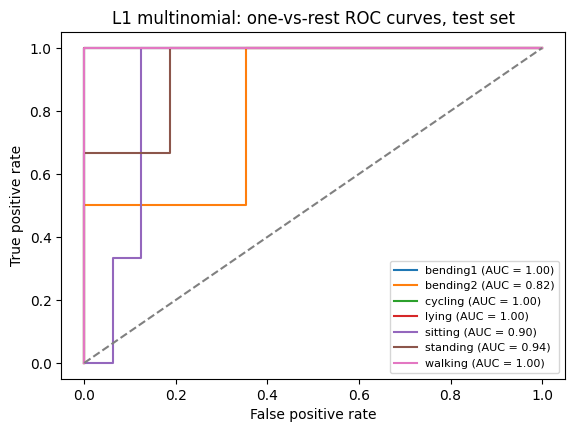

Macro-average AUC: 0.951


In [64]:
cv4 = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
classes = np.array(activities)


def multiclass_report(model, X, y, name):
    prob = model.predict_proba(X)
    pred = model.classes_[prob.argmax(axis=1)]
    acc = accuracy_score(y, pred)
    print(f'{name}: test accuracy = {acc:.3f}, test error = {1 - acc:.3f}')
    print(pd.DataFrame(confusion_matrix(y, pred, labels=model.classes_),
                       index=['actual ' + c for c in model.classes_],
                       columns=model.classes_))
    # one ROC curve per activity: that activity against all the others
    plt.figure(figsize=(6.5, 4.5))
    aucs = {}
    for i, c in enumerate(model.classes_):
        fpr, tpr, _ = roc_curve(y == c, prob[:, i])
        aucs[c] = roc_auc_score(y == c, prob[:, i])
        plt.plot(fpr, tpr, label=f'{c} (AUC = {aucs[c]:.2f})')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.xlabel('False positive rate')
    plt.ylabel('True positive rate')
    plt.title(name + ': one-vs-rest ROC curves, test set')
    plt.legend(fontsize=8, loc='lower right')
    plt.show()
    print(f'Macro-average AUC: {np.mean(list(aucs.values())):.3f}')
    return acc, np.mean(list(aucs.values()))


def multinomial_l1(C=1.0):
    major_minor = tuple(int(v) for v in sklearn.__version__.split('.')[:2])
    kw = {'l1_ratio': 1} if major_minor >= (1, 8) else {'penalty': 'l1'}
    return make_pipeline(StandardScaler(),
                         LogisticRegression(solver='saga', C=C, max_iter=5000, tol=1e-3,
                                            random_state=SEED, **kw))


rows = []
for l in range(1, 21):
    search = GridSearchCV(multinomial_l1(), {'logisticregression__C': Cs},
                          cv=cv4, scoring='accuracy', n_jobs=-1).fit(Xtr[l], y_train_multi)
    rows.append((l, search.best_params_['logisticregression__C'], search.best_score_))

multi_scores = pd.DataFrame(rows, columns=['l', 'C', 'CV accuracy'])
print(multi_scores.round(3).to_string(index=False))

best_m = multi_scores.sort_values(['CV accuracy', 'l'], ascending=[False, True]).iloc[0]
m_l, m_C = int(best_m['l']), float(best_m['C'])
multi_model = multinomial_l1(m_C).fit(Xtr[m_l], y_train_multi)
print()
print('Best (l, C):', (m_l, round(m_C, 3)), ' CV accuracy:', round(best_m['CV accuracy'], 3))
print()
mn_acc, mn_auc = multiclass_report(multi_model, Xte[m_l], y_test_multi, 'L1 multinomial')

The best pair is **(l, C) = (2, 31.6)** with a CV accuracy of 0.927; for larger `l` the CV accuracy is mostly lower (0.825 to 0.898 for `l` = 3 to 20). On the test set the **test error is 0.211** (4 of 19 wrong, accuracy 0.789) and the macro-average AUC is 0.951. Cycling and walking are always correct. The mistakes are: one `bending2` predicted as `sitting`, one `sitting` as `bending1`, one `sitting` as `standing`, and one `standing` as `lying`.

#### ii. Naive Bayes

Gaussian Naive Bayes models each feature within each class using a normal distribution. Multinomial Naive Bayes is intended for count-like features; here it is applied to the non-negative mean, standard deviation and maximum features as requested. I kept `var_smoothing` for GaussianNB and `alpha` for MultinomialNB at their default values. Only `l` was selected using stratified 4-fold cross-validation, with ties going to the smaller `l`.

Gaussian NB: CV accuracy for l = 1..20
[0.913 0.885 0.871 0.871 0.885 0.827 0.885 0.828 0.798 0.799 0.827 0.855
 0.74  0.826 0.827 0.812 0.797 0.841 0.827 0.826]
best l: 1
Gaussian NB: test accuracy = 0.895, test error = 0.105
                 bending1  bending2  cycling  lying  sitting  standing  \
actual bending1         2         0        0      0        0         0   
actual bending2         0         1        0      0        1         0   
actual cycling          0         0        3      0        0         0   
actual lying            0         0        0      3        0         0   
actual sitting          0         0        0      0        3         0   
actual standing         0         0        0      0        1         2   
actual walking          0         0        0      0        0         0   

                 walking  
actual bending1        0  
actual bending2        0  
actual cycling         0  
actual lying           0  
actual sitting         0  
actual standing   

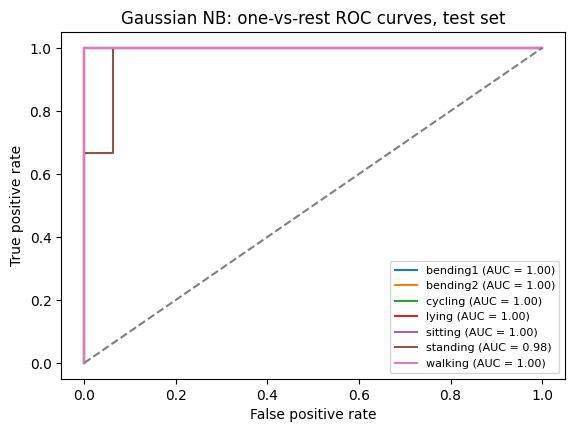

Macro-average AUC: 0.997

Multinomial NB: CV accuracy for l = 1..20
[0.797 0.825 0.884 0.898 0.855 0.855 0.883 0.855 0.884 0.824 0.855 0.855
 0.855 0.868 0.824 0.84  0.854 0.839 0.84  0.811]
best l: 4
Multinomial NB: test accuracy = 0.842, test error = 0.158
                 bending1  bending2  cycling  lying  sitting  standing  \
actual bending1         2         0        0      0        0         0   
actual bending2         0         2        0      0        0         0   
actual cycling          0         0        3      0        0         0   
actual lying            0         0        0      2        1         0   
actual sitting          0         0        0      0        2         1   
actual standing         0         0        0      0        1         2   
actual walking          0         0        0      0        0         0   

                 walking  
actual bending1        0  
actual bending2        0  
actual cycling         0  
actual lying           0  
actual sittin

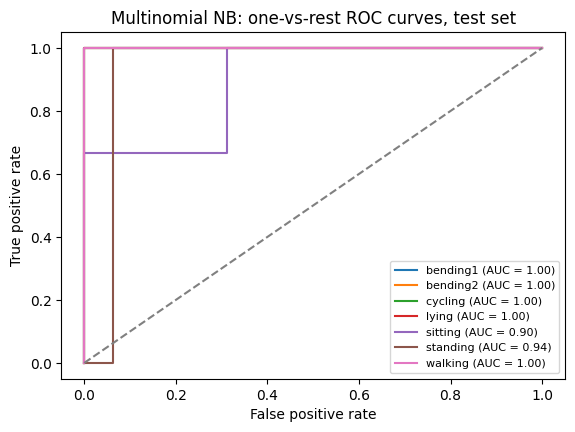

Macro-average AUC: 0.976



In [65]:
nb_cv = {}
nb_results = {}
for name, make_model in [('Gaussian', GaussianNB), ('Multinomial', MultinomialNB)]:
    scores = [cross_val_score(make_model(), Xtr[l], y_train_multi, cv=cv4, scoring='accuracy').mean()
              for l in range(1, 21)]
    nb_cv[name] = scores
    nb_l = int(np.argmax(scores)) + 1          # argmax gives the smallest l when there is a tie
    print(f'{name} NB: CV accuracy for l = 1..20')
    print(np.round(scores, 3))
    print('best l:', nb_l)
    model = make_model().fit(Xtr[nb_l], y_train_multi)
    nb_results[name] = (nb_l,) + multiclass_report(model, Xte[nb_l], y_test_multi, name + ' NB')
    print()

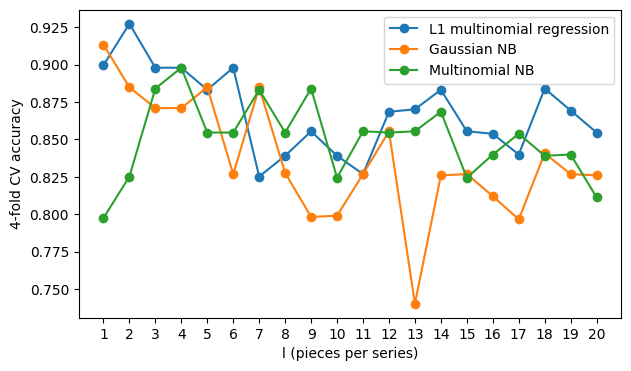

In [66]:
plt.figure(figsize=(7, 4))
plt.plot(multi_scores['l'], multi_scores['CV accuracy'], marker='o', label='L1 multinomial regression')
plt.plot(range(1, 21), nb_cv['Gaussian'], marker='o', label='Gaussian NB')
plt.plot(range(1, 21), nb_cv['Multinomial'], marker='o', label='Multinomial NB')
plt.xticks(range(1, 21))
plt.xlabel('l (pieces per series)')
plt.ylabel('4-fold CV accuracy')
plt.legend()
plt.show()

**Gaussian NB** has its best CV accuracy at `l = 1` (0.913); the test accuracy is 0.895 (test error 0.105, 2 mistakes) and the macro AUC 0.997. **Multinomial NB** has its best CV accuracy at `l = 4` (0.898); the test accuracy is 0.842 (test error 0.158) and the macro AUC 0.976. Gaussian NB has the lower test error and the higher AUC. In the plot the CV accuracy of Gaussian NB and of the L1 model is highest for small `l` (`l` = 1 and 2) and is lower for larger `l`.

#### iii. Comparison

In [67]:
final = pd.DataFrame({
    'l': [m_l, nb_results['Gaussian'][0], nb_results['Multinomial'][0]],
    'CV accuracy': [best_m['CV accuracy'], max(nb_cv['Gaussian']), max(nb_cv['Multinomial'])],
    'test accuracy': [mn_acc, nb_results['Gaussian'][1], nb_results['Multinomial'][1]],
    'test error': [1 - mn_acc, 1 - nb_results['Gaussian'][1], 1 - nb_results['Multinomial'][1]],
    'macro AUC': [mn_auc, nb_results['Gaussian'][2], nb_results['Multinomial'][2]],
}, index=['L1 multinomial regression', 'Gaussian NB', 'Multinomial NB'])
final.round(3)

,l,CV accuracy,test accuracy,test error,macro AUC
L1 multinomial regression,2,0.927,0.789,0.211,0.951
Gaussian NB,1,0.913,0.895,0.105,0.997
Multinomial NB,4,0.898,0.842,0.158,0.976


L1 multinomial regression has the highest CV accuracy, 0.927, followed by Gaussian NB at 0.913 and Multinomial NB at 0.898. On the test set, Gaussian NB gets 17 of 19 instances correct, compared with 16 for Multinomial NB and 15 for L1 multinomial regression.

Gaussian NB performs best on this test set, with test error 0.105 and macro-average AUC 0.997. It uses 18 features at l = 1, with its other hyperparameters left at their defaults. All three models classify the test cycling and walking instances correctly. These results favor Gaussian NB for this experiment, although the test set contains only 19 instances.

## 3. ISLR 4.8.3

For class $k$ the density is $f_k(x)=\dfrac{1}{\sqrt{2\pi}\,\sigma_k}\exp\!\Big(-\dfrac{(x-\mu_k)^2}{2\sigma_k^2}\Big)$ and the posterior probability is

$$p_k(x)=\frac{\pi_k f_k(x)}{\sum_{l=1}^{K}\pi_l f_l(x)} .$$

The denominator is the same for every class, so the Bayes classifier puts $x$ in the class with the largest $\pi_k f_k(x)$. The log is increasing, so it is enough to maximize

$$\log\big(\pi_k f_k(x)\big)=\log\pi_k-\log\sigma_k-\tfrac12\log 2\pi-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Dropping the constant $-\tfrac12\log 2\pi$ and expanding the square gives the discriminant

$$\delta_k(x)=-\frac{x^2}{2\sigma_k^2}+\frac{\mu_k}{\sigma_k^2}\,x-\frac{\mu_k^2}{2\sigma_k^2}-\log\sigma_k+\log\pi_k .$$

The coefficient of $x^2$ is $-1/(2\sigma_k^2)$, which depends on $k$. For two classes $j\neq k$ with different variances, the decision boundary $\delta_j(x)=\delta_k(x)$
still has an $x^2$ term, so it is **quadratic**, not linear. Only when all the $\sigma_k$ are equal do the $x^2$ terms cancel in $\delta_j-\delta_k$, which gives the linear boundary of LDA.

## 4. ISLR 4.8.7

Here $\pi_{Yes}=0.8$, $\pi_{No}=0.2$, $\mu_{Yes}=10$, $\mu_{No}=0$, $\sigma^2=36$ for both classes and $x=4$. By Bayes' theorem

$$P(Yes\mid X=4)=\frac{\pi_{Yes}f_{Yes}(4)}{\pi_{Yes}f_{Yes}(4)+\pi_{No}f_{No}(4)}
=\frac{0.8\,e^{-(4-10)^2/72}}{0.8\,e^{-(4-10)^2/72}+0.2\,e^{-(4-0)^2/72}}
=\frac{0.8\,e^{-0.5}}{0.8\,e^{-0.5}+0.2\,e^{-0.222}} .$$

The common factor $1/\sqrt{2\pi\cdot 36}$ of the two densities cancels. Numerically:

In [68]:
num = 0.8 * np.exp(-(4 - 10) ** 2 / (2 * 36))
den = num + 0.2 * np.exp(-(4 - 0) ** 2 / (2 * 36))
print(round(num, 4), round(den - num, 4), round(num / den, 4))

0.4852 0.1601 0.7519


So the probability that the company issues a dividend this year is about **0.752 (75.2%)**.